# 第 18 课｜几何布朗运动

> **数据身份**：固定随机种子生成的模拟教学数据，不是真实证券行情。  
> **环境**：`pkm-quant` · Python 3.11 · 默认离线运行。  
> **课程原始材料**：`18_youtube-IP4xUfcXvRY/index.html`  
> **所属模块**：P1-M4 · 随机模型与衍生品风险

## 本节量化问题

GBM 为什么保证价格为正，又为什么难以描述真实市场？

## 准确定义与策略报告位置

GBM 假设对数收益具有常数漂移和波动，连续路径且增量独立，解析上便于模拟和定价。

- **核心关系**：GBM：dS/S=μdt+σdW；离散精确步进 S_(t+Δ)=S_t exp[(μ-σ²/2)Δ+σ√ΔZ]。
- **写入报告**：价格过程假设与情景生成
- **P2 衔接**：P2 第 32、48 课：向量化和分布工具。


## 运行环境与数据契约

先确认项目、数据目录和数据身份。后续联网数据源必须通过适配层进入，不能改变本 Notebook 的研究计算口径。

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "data" / "fixtures").exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data" / "fixtures"
OUTPUT_DIR = ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RANDOM_SEED = 365
print("项目:", ROOT)
print("数据:", DATA_DIR)
print("数据身份: 固定随机种子生成的模拟教学数据，不是真实证券行情")


项目: /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p1-quant-foundations
数据: /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p1-quant-foundations/data/fixtures
数据身份: 固定随机种子生成的模拟教学数据，不是真实证券行情


## 用 GBM 精确离散式生成路径

代码中的 `mu` 是真实世界漂移假设；风险中性定价时应替换为适当的风险中性漂移。

一年终值中位数: 103.04


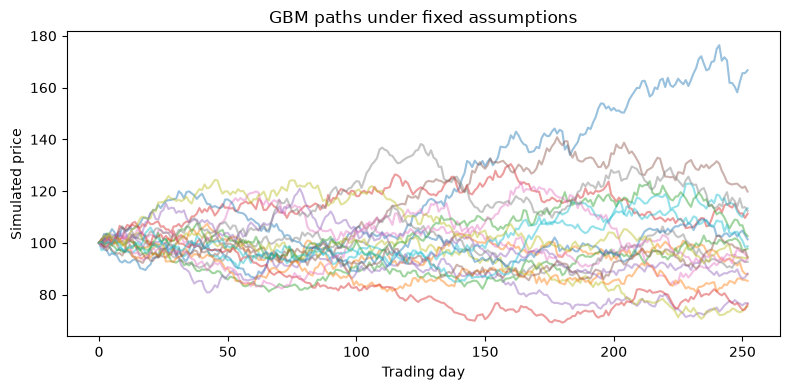

In [2]:
rng = np.random.default_rng(365)
spot, mu, sigma = 100.0, 0.06, 0.22
steps, paths = 252, 200
dt = 1.0 / steps
z = rng.standard_normal((steps, paths))
log_increments = (mu - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * z
prices = spot * np.exp(np.vstack([np.zeros(paths), np.cumsum(log_increments, axis=0)]))

assert prices.shape == (steps + 1, paths)
print("一年终值中位数:", round(float(np.median(prices[-1])), 2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(prices[:, :20], alpha=0.45)
ax.set(title="GBM paths under fixed assumptions", xlabel="Trading day", ylabel="Simulated price")
plt.tight_layout()
plt.show()

## 方法边界与阶段验收

真实市场存在跳跃、厚尾、波动聚集和制度变化；漂移在短样本中难估。

完成本课后应能：

1. 不看课程材料准确解释核心概念和公式符号；
2. 用小样本手工核对 Notebook 的关键结果；
3. 说明结果能支持什么判断、不能支持什么判断；
4. 指出它在策略报告中的位置，以及仍缺少的数据、成本或稳健性证据。
